## Setup

In [3]:
import json
import os
import site
import subprocess
import sys
import zipfile
from pathlib import Path

# Anaconda's NumPy and pip's PyTorch each ship an OpenMP runtime on Windows; let them coexist.
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix   # NEW: confusion_matrix

# PyTorch: import it, or install the CPU build into this kernel's Python if it is missing.
try:
    import torch
except ModuleNotFoundError:
    print("PyTorch is not installed for", sys.executable, "- installing it once (a few hundred MB) ...")
    pip = [sys.executable, "-m", "pip", "install", "torch"]
    if subprocess.run(pip + ["--index-url", "https://download.pytorch.org/whl/cpu"]).returncode != 0:
        subprocess.run(pip, check=True)      # PyTorch's own index unreachable: fall back to PyPI
    site.addsitedir(site.getusersitepackages())   # pip may use the per-user folder, which some kernels skip
    import torch
from torch import nn

# Use a GPU when PyTorch can see one (NVIDIA "cuda" or Apple "mps"); otherwise the CPU.
# Both labs finish in under a minute on a CPU, so nothing here needs a GPU.
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
torch.manual_seed(42)
PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)
RESULTS = PROJECT_ROOT / "results" / "lab7"          # NEW: all Lab 7 outputs go here
RESULTS.mkdir(parents=True, exist_ok=True)           # NEW

def save_fig(name):                                  # NEW: save the current figure as a PNG
    path = RESULTS / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("saved", path.relative_to(PROJECT_ROOT))

print("Python", sys.version.split()[0], "at", sys.executable)
print("PyTorch", torch.__version__, "| device:", DEVICE,
      f"({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")

# NEW: record the environment for the checklist
(RESULTS / "environment.json").write_text(json.dumps({
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "device": str(DEVICE),
}, indent=2))

Python 3.11.14 at C:\Users\Acer\anaconda3\python.exe
PyTorch 2.15.0+cpu | device: cpu 


69

## Part A: Images as tensors

fit: torch.Size([2868, 1, 8, 8])  validation: torch.Size([955, 1, 8, 8])  test: torch.Size([1797, 1, 8, 8])
saved results\lab7\A_sample_training_digits.png


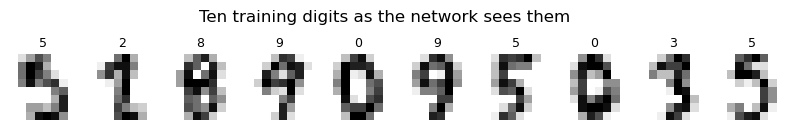

In [4]:
columns = [f"pixel_{i}" for i in range(64)] + ["label"]
with zipfile.ZipFile(DATA / "optical_recognition_handwritten_digits.zip") as archive:
    members = {Path(name).name: name for name in archive.namelist()}
    train = pd.read_csv(archive.open(members["optdigits.tra"]), header=None, names=columns)
    test = pd.read_csv(archive.open(members["optdigits.tes"]), header=None, names=columns)

def to_tensors(frame):
    X = torch.tensor(frame.drop(columns="label").to_numpy(), dtype=torch.float32)
    X = X.reshape(-1, 1, 8, 8) / 16.0            # (rows, channels, height, width), values in [0, 1]
    y = torch.tensor(frame["label"].to_numpy(), dtype=torch.long)
    return X.to(DEVICE), y.to(DEVICE)         # tensors live on the chosen device

X_dev, y_dev = to_tensors(train)
X_test, y_test = to_tensors(test)
perm = torch.randperm(len(X_dev), generator=torch.Generator().manual_seed(42))
n_val = len(X_dev) // 4
X_val, y_val = X_dev[perm[:n_val]], y_dev[perm[:n_val]]
X_fit, y_fit = X_dev[perm[n_val:]], y_dev[perm[n_val:]]
print("fit:", X_fit.shape, " validation:", X_val.shape, " test:", X_test.shape)

# NEW: save the split sizes
(RESULTS / "data_split.json").write_text(json.dumps({
    "fit": list(X_fit.shape), "validation": list(X_val.shape), "test": list(X_test.shape),
}, indent=2))

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, image, label in zip(axes, X_fit[:10], y_fit[:10]):
    ax.imshow(image[0].cpu(), cmap="gray_r")     # matplotlib wants a CPU tensor
    ax.set_title(int(label), fontsize=9)
    ax.axis("off")
plt.suptitle("Ten training digits as the network sees them", y=1.05)
save_fig("A_sample_training_digits")             # NEW
plt.show()

## Part B: A first neural network and the training loop

In [5]:
def make_mlp():
    return nn.Sequential(
        nn.Flatten(),                  # 1 x 8 x 8 -> 64
        nn.Linear(64, 128), nn.ReLU(),
        nn.Linear(128, 10),            # ten class scores
    )

mlp = make_mlp().to(DEVICE)
print(mlp)
print("trainable weights:", sum(p.numel() for p in mlp.parameters()))

# NEW: save the architecture summary
(RESULTS / "B_mlp_architecture.txt").write_text(
    f"{mlp}\ntrainable weights: {sum(p.numel() for p in mlp.parameters())}\n")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=64, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
trainable weights: 9610


210

In [6]:
def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(dim=1) == y).float().mean().item()

def train_classifier(model, X, y, X_v, y_v, epochs=20, lr=3e-3, batch_size=32):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    history = {"train": [], "validation": []}
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X))
        for start in range(0, len(X), batch_size):
            batch = order[start:start + batch_size]
            optimizer.zero_grad()                     # forget the previous gradients
            loss = loss_fn(model(X[batch]), y[batch])
            loss.backward()                           # backpropagation: gradient for every weight
            optimizer.step()                          # move every weight a small step
        history["train"].append(accuracy(model, X, y))
        history["validation"].append(accuracy(model, X_v, y_v))
    return history

def save_history(history, name):                      # NEW: per-epoch accuracies as CSV
    frame = pd.DataFrame(history)
    frame.index = range(1, len(frame) + 1)
    frame.index.name = "epoch"
    frame.to_csv(RESULTS / f"{name}.csv")
    print("saved", (RESULTS / f"{name}.csv").relative_to(PROJECT_ROOT))

torch.manual_seed(42)
mlp_history = train_classifier(mlp, X_fit, y_fit, X_val, y_val)
print("dense network: validation accuracy =", round(mlp_history["validation"][-1], 4))
save_history(mlp_history, "B_mlp_history")            # NEW

dense network: validation accuracy = 0.9759
saved results\lab7\B_mlp_history.csv


saved results\lab7\B_mlp_accuracy_curve.png


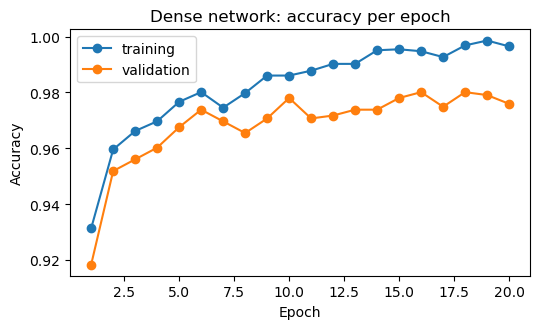

In [7]:
def plot_history(history, title, name=None):          # NEW: optional name to save under
    plt.figure(figsize=(5.5, 3.4))
    plt.plot(range(1, len(history["train"]) + 1), history["train"], marker="o", label="training")
    plt.plot(range(1, len(history["validation"]) + 1), history["validation"],
             marker="o", label="validation")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    if name:                                          # NEW
        save_fig(name)
    plt.show()

plot_history(mlp_history, "Dense network: accuracy per epoch", "B_mlp_accuracy_curve")   # NEW: name

## Part C: A convolutional network

In [8]:
def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 16 x 4 x 4
        nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32 x 2 x 2
        nn.Flatten(),                                                              # 128
        nn.Linear(32 * 2 * 2, 64), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(64, 10),
    )

cnn = make_cnn().to(DEVICE)
print("trainable weights:", sum(p.numel() for p in cnn.parameters()))
shape_lines = [f"trainable weights: {sum(p.numel() for p in cnn.parameters())}"]   # NEW
sample = X_fit[:1]
for layer in cnn:
    sample = layer(sample)
    if isinstance(layer, (nn.Conv2d, nn.MaxPool2d, nn.Flatten, nn.Linear)):
        line = f"{layer.__class__.__name__:10s} -> {tuple(sample.shape[1:])}"
        print(line)
        shape_lines.append(line)                                                   # NEW
(RESULTS / "C_cnn_architecture.txt").write_text(f"{cnn}\n\n" + "\n".join(shape_lines) + "\n")   # NEW

trainable weights: 13706
Conv2d     -> (16, 8, 8)
MaxPool2d  -> (16, 4, 4)
Conv2d     -> (32, 4, 4)
MaxPool2d  -> (32, 2, 2)
Flatten    -> (128,)
Linear     -> (64,)
Linear     -> (10,)


747

CNN: validation accuracy = 0.9812


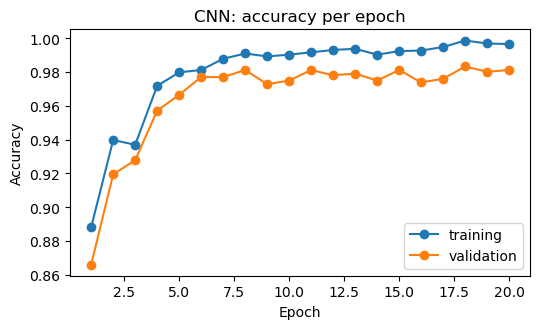

In [9]:
torch.manual_seed(42)
cnn_history = train_classifier(cnn, X_fit, y_fit, X_val, y_val)
print("CNN: validation accuracy =", round(cnn_history["validation"][-1], 4))
plot_history(cnn_history, "CNN: accuracy per epoch")

logistic on PCA (Lab 4)    test accuracy = 0.9477
dense network              test accuracy = 0.9583
CNN                        test accuracy = 0.9683
saved results\lab7\C_test_accuracy_comparison.png


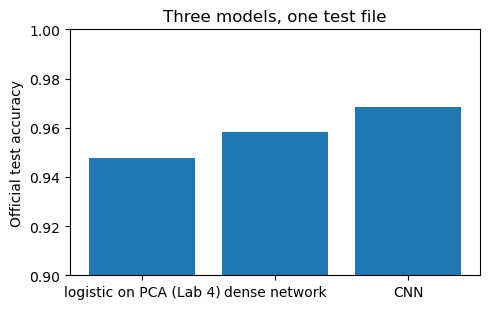

In [10]:
test_scores = {
    "logistic on PCA (Lab 4)": 0.9477,
    "dense network": accuracy(mlp, X_test, y_test),
    "CNN": accuracy(cnn, X_test, y_test),
}
for name, value in test_scores.items():
    print(f"{name:26s} test accuracy = {value:.4f}")

# NEW: save the comparison table
pd.Series(test_scores, name="test_accuracy").rename_axis("model").to_csv(RESULTS / "C_test_scores.csv")

plt.figure(figsize=(5, 3.2))
plt.bar(list(test_scores), list(test_scores.values()))
plt.ylim(0.9, 1.0)
plt.ylabel("Official test accuracy")
plt.title("Three models, one test file")
plt.tight_layout()
save_fig("C_test_accuracy_comparison")           # NEW
plt.show()

saved results\lab7\C_cnn_confusion_matrix.png


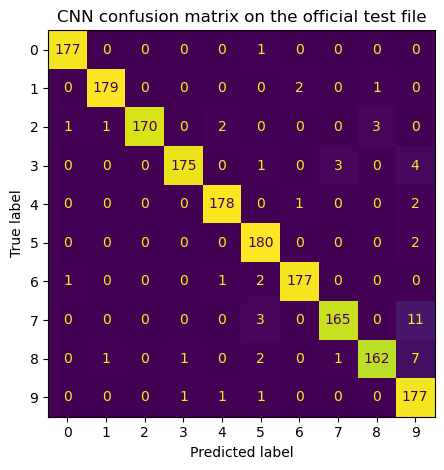

true  predicted
7     9            11
8     9             7
3     9             4
2     8             3
3     7             3
7     5             3
2     4             2
8     5             2
4     9             2
5     9             2
Name: count, dtype: int64
saved results\lab7\C_cnn_mistakes.png


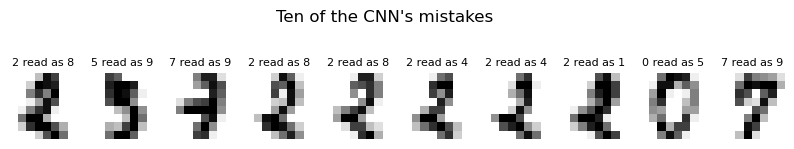

In [11]:
cnn.eval()
with torch.no_grad():
    test_pred = cnn(X_test).argmax(dim=1)

y_true_np, y_pred_np = y_test.cpu().numpy(), test_pred.cpu().numpy()   # NEW: reused below

ConfusionMatrixDisplay.from_predictions(y_true_np, y_pred_np, colorbar=False)
plt.title("CNN confusion matrix on the official test file")
plt.tight_layout()
save_fig("C_cnn_confusion_matrix")               # NEW
plt.show()

# NEW: confusion matrix as a table (rows = true digit, columns = predicted digit)
pd.DataFrame(confusion_matrix(y_true_np, y_pred_np),
             index=[f"true_{d}" for d in range(10)],
             columns=[f"pred_{d}" for d in range(10)]).to_csv(RESULTS / "C_cnn_confusion_matrix.csv")

# NEW: every misclassified test digit, plus the most frequent confusion pairs
mistakes = pd.DataFrame({"test_index": np.flatnonzero(y_true_np != y_pred_np)})
mistakes["true"] = y_true_np[mistakes["test_index"]]
mistakes["predicted"] = y_pred_np[mistakes["test_index"]]
mistakes.to_csv(RESULTS / "C_cnn_mistakes.csv", index=False)
top_confusions = mistakes.groupby(["true", "predicted"]).size().sort_values(ascending=False).rename("count")
top_confusions.to_csv(RESULTS / "C_cnn_top_confusions.csv")
print(top_confusions.head(10))

wrong = torch.nonzero(test_pred != y_test).flatten()[:10]
fig, axes = plt.subplots(1, len(wrong), figsize=(10, 1.6))
for ax, i in zip(axes, wrong):
    ax.imshow(X_test[i, 0].cpu(), cmap="gray_r")
    ax.set_title(f"{int(y_test[i])} read as {int(test_pred[i])}", fontsize=8)
    ax.axis("off")
plt.suptitle("Ten of the CNN's mistakes", y=1.1)
save_fig("C_cnn_mistakes")                       # NEW
plt.show()

saved results\lab7\C_cnn_first_layer_filters.png


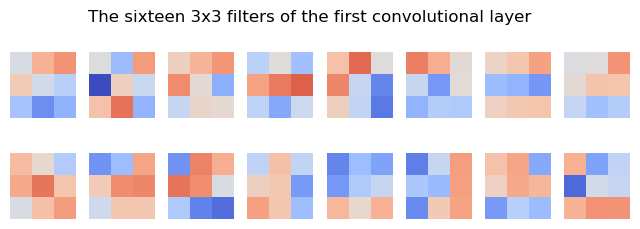

In [12]:
filters = cnn[0].weight.detach().cpu()[:, 0]
fig, axes = plt.subplots(2, 8, figsize=(8, 2.4))
for ax, kernel in zip(axes.flat, filters):
    ax.imshow(kernel, cmap="coolwarm", vmin=-filters.abs().max(), vmax=filters.abs().max())
    ax.axis("off")
plt.suptitle("The sixteen 3x3 filters of the first convolutional layer", y=1.02)
save_fig("C_cnn_first_layer_filters")            # NEW
plt.show()

## Part D: Save the weights with a card

In [13]:
weights_path = MODELS / "digits_cnn.pt"
torch.save(cnn.state_dict(), weights_path)

card = {
    "task": "classify 8x8 handwritten digits (0-9)",
    "input": "tensor of shape (n, 1, 8, 8), pixel values divided by 16",
    "architecture": "make_cnn() in Lab 7: conv16-pool-conv32-pool-dense64-dense10",
    "training": {"epochs": 20, "learning_rate": 3e-3, "batch_size": 32, "seed": 42},
    "official_test_accuracy": round(test_scores["CNN"], 4),
    "torch_version": torch.__version__,
    "trained_on": str(DEVICE),
}
(MODELS / "digits_cnn_card.json").write_text(json.dumps(card, indent=2))

restored = make_cnn().to(DEVICE)
restored.load_state_dict(torch.load(weights_path, map_location=DEVICE, weights_only=True))
restored.eval()
with torch.no_grad():
    same = torch.equal(restored(X_test).argmax(dim=1), test_pred)
size_kb = weights_path.stat().st_size / 1024
print(f"saved {weights_path.name} ({size_kb:.0f} KB); reload reproduces predictions: {same}")

# NEW: one summary file covering the whole lab
summary = {
    "device": str(DEVICE),
    "torch_version": torch.__version__,
    "final_validation_accuracy": {
        "dense network": round(mlp_history["validation"][-1], 4),
        "CNN": round(cnn_history["validation"][-1], 4),
    },
    "best_validation_epoch": {
        "dense network": int(np.argmax(mlp_history["validation"]) + 1),
        "CNN": int(np.argmax(cnn_history["validation"]) + 1),
    },
    "test_accuracy": {k: round(v, 4) for k, v in test_scores.items()},
    "cnn_test_mistakes": int(len(mistakes)),
    "weights_file": str(weights_path.relative_to(PROJECT_ROOT)),
    "weights_size_kb": round(size_kb, 1),
    "reload_matches": bool(same),
}
(RESULTS / "D_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

saved digits_cnn.pt (57 KB); reload reproduces predictions: True
{
  "device": "cpu",
  "torch_version": "2.15.0+cpu",
  "final_validation_accuracy": {
    "dense network": 0.9759,
    "CNN": 0.9812
  },
  "best_validation_epoch": {
    "dense network": 16,
    "CNN": 18
  },
  "test_accuracy": {
    "logistic on PCA (Lab 4)": 0.9477,
    "dense network": 0.9583,
    "CNN": 0.9683
  },
  "cnn_test_mistakes": 57,
  "weights_file": "models\\digits_cnn.pt",
  "weights_size_kb": 57.1,
  "reload_matches": true
}


## Try it youself

saved results\lab7\T1_cnn_history_5_epochs.csv
saved results\lab7\T1_cnn_history_40_epochs.csv
saved results\lab7\T1_cnn_5_vs_40_epochs.png


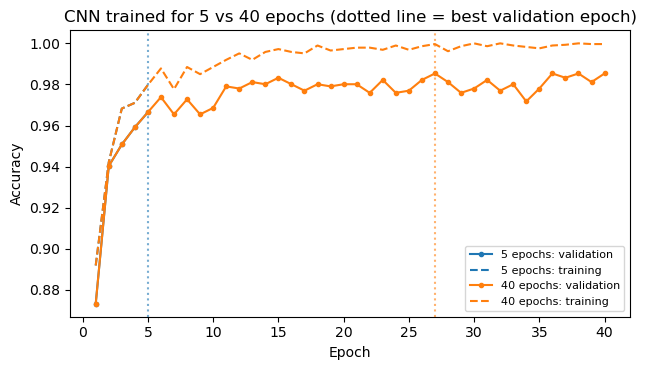

        final_train  final_validation  best_validation  best_epoch    test
epochs                                                                    
5            0.9798            0.9665           0.9665         5.0  0.9494
40           0.9997            0.9853           0.9853        27.0  0.9666


In [14]:
# Train two fresh CNNs from the same seed: one for 5 epochs, one for 40
runs = {}
for n_epochs in (5, 40):
    torch.manual_seed(42)
    model = make_cnn().to(DEVICE)
    history = train_classifier(model, X_fit, y_fit, X_val, y_val, epochs=n_epochs)
    best_epoch = int(np.argmax(history["validation"]) + 1)
    runs[n_epochs] = {
        "history": history,
        "final_train": history["train"][-1],
        "final_validation": history["validation"][-1],
        "best_validation": max(history["validation"]),
        "best_epoch": best_epoch,
        "test": accuracy(model, X_test, y_test),
    }
    save_history(history, f"T1_cnn_history_{n_epochs}_epochs")

# Validation (solid) and training (dashed) curves on one plot
plt.figure(figsize=(6.5, 3.8))
for n_epochs, r in runs.items():
    epochs = range(1, n_epochs + 1)
    line, = plt.plot(epochs, r["history"]["validation"], marker="o", markersize=3,
                     label=f"{n_epochs} epochs: validation")
    plt.plot(epochs, r["history"]["train"], linestyle="--", color=line.get_color(),
             label=f"{n_epochs} epochs: training")
    plt.axvline(r["best_epoch"], color=line.get_color(), linestyle=":", alpha=0.6)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN trained for 5 vs 40 epochs (dotted line = best validation epoch)")
plt.legend(fontsize=8)
plt.tight_layout()
save_fig("T1_cnn_5_vs_40_epochs")
plt.show()

t1_table = pd.DataFrame({n: {k: v for k, v in r.items() if k != "history"} for n, r in runs.items()}).T
t1_table.index.name = "epochs"
t1_table.to_csv(RESULTS / "T1_epochs_comparison.csv")
print(t1_table.round(4))

In [15]:
def make_cnn_one_block():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 16 x 4 x 4
        nn.Flatten(),                                                              # 256
        nn.Linear(16 * 4 * 4, 64), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(64, 10),
    )

# Check the shapes
small = make_cnn_one_block().to(DEVICE)
sample = X_fit[:1]
for layer in small:
    sample = layer(sample)
    if isinstance(layer, (nn.Conv2d, nn.MaxPool2d, nn.Flatten, nn.Linear)):
        print(f"{layer.__class__.__name__:10s} -> {tuple(sample.shape[1:])}")

Conv2d     -> (16, 8, 8)
MaxPool2d  -> (16, 4, 4)
Flatten    -> (256,)
Linear     -> (64,)
Linear     -> (10,)


                       parameters  validation_mean  validation_std  test_mean  \
model                                                                           
one block                   17258           0.9784          0.0054     0.9735   
two blocks (original)       13706           0.9780          0.0021     0.9681   

                       test_std  
model                            
one block                0.0052  
two blocks (original)    0.0022  

Contribution of the second block (mean test accuracy): -0.0054  (~-10 of 1797 test digits)
saved results\lab7\T2_one_vs_two_blocks_validation.png


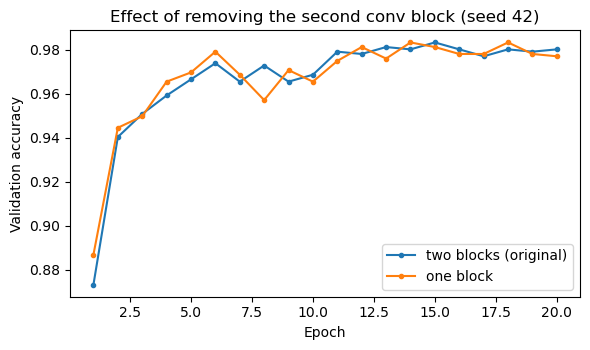

saved results\lab7\T2_one_vs_two_blocks_test.png


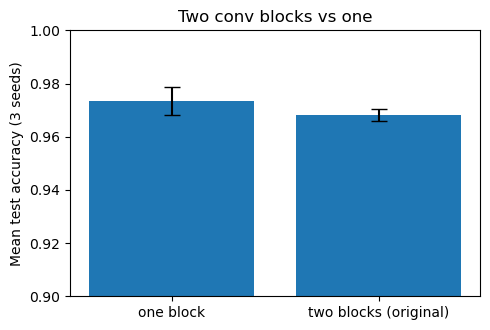

In [16]:
SEEDS = [42, 43, 44]
builders = {"two blocks (original)": make_cnn, "one block": make_cnn_one_block}
rows, histories = [], {}

for name, build in builders.items():
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = build().to(DEVICE)
        history = train_classifier(model, X_fit, y_fit, X_val, y_val)   # 20 epochs, same as Part C
        rows.append({
            "model": name,
            "seed": seed,
            "parameters": sum(p.numel() for p in model.parameters()),
            "final_validation": history["validation"][-1],
            "best_validation": max(history["validation"]),
            "test": accuracy(model, X_test, y_test),
        })
        if seed == 42:
            histories[name] = history

t2_runs = pd.DataFrame(rows)
t2_runs.to_csv(RESULTS / "T2_ablation_all_runs.csv", index=False)

t2_summary = t2_runs.groupby("model").agg(
    parameters=("parameters", "first"),
    validation_mean=("final_validation", "mean"),
    validation_std=("final_validation", "std"),
    test_mean=("test", "mean"),
    test_std=("test", "std"),
)
t2_summary.to_csv(RESULTS / "T2_ablation_summary.csv")
print(t2_summary.round(4))

diff = t2_summary.loc["two blocks (original)", "test_mean"] - t2_summary.loc["one block", "test_mean"]
print(f"\nContribution of the second block (mean test accuracy): {diff:+.4f}"
      f"  (~{diff * len(X_test):+.0f} of {len(X_test)} test digits)")

# Validation curves for seed 42
plt.figure(figsize=(6, 3.6))
for name, history in histories.items():
    plt.plot(range(1, len(history["validation"]) + 1), history["validation"], marker="o", markersize=3, label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Effect of removing the second conv block (seed 42)")
plt.legend()
plt.tight_layout()
save_fig("T2_one_vs_two_blocks_validation")
plt.show()

# Mean test accuracy with spread across seeds
plt.figure(figsize=(5, 3.4))
plt.bar(t2_summary.index, t2_summary["test_mean"], yerr=t2_summary["test_std"], capsize=6)
plt.ylim(0.9, 1.0)
plt.ylabel("Mean test accuracy (3 seeds)")
plt.title("Two conv blocks vs one")
plt.tight_layout()
save_fig("T2_one_vs_two_blocks_test")
plt.show()